443
['s_ra', 's_dec', 'facility_name', 'instrument_name', 'dataproduct_subtype', 'calib_level', 'dataproduct_type', 'energy_bandpassname', 'energy_emband', 'obs_id', 's_resolution', 'em_min', 'em_max', 'em_res_power', 'proposal_title', 'access_url', 'access_format', 'access_estsize', 't_exptime', 's_region', 'obs_collection', 'obs_intent', 'algorithm_name', 'facility_keywords', 'instrument_keywords', 'environment_photometric', 'proposal_id', 'proposal_pi', 'proposal_project', 'target_name', 'target_type', 'target_standard', 'target_moving', 'target_keywords', 'obs_release_date', 's_xel1', 's_xel2', 's_pixel_scale', 'position_timedependent', 't_min', 't_max', 't_resolution', 't_xel', 'obs_publisher_did', 's_fov', 'em_xel', 'pol_states', 'pol_xel', 'cloud_access', 'o_ucd', 'upload_row_id']
https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W18_1B/l2b-v27-2026-196/1/level2_2025W18_1B_0074_2D1_spx_l2b-v27-2026-196.fits
Filename: /home/rafael/.cache/astropy/download/url/2edb0eda8

Gtk-Message: 09:03:54.994: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.


EXTNAME: IMAGE
NAXIS1: 2040
NAXIS2: 2040
BUNIT: MJy / sr
DETECTOR: 1
OBSID: 2025W18_1B_0074_2
DATE: 2026-07-16T03:19:15.597
PSF_FWHM: 7.530770327317724
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 303.877766184 40.5489585415
CRPIX : 1020.5 1020.5
PC1_1 PC1_2  : -0.00161399858549 -0.000503359988208
PC2_1 PC2_2  : -0.000566313443671 0.00163301103545
CDELT : 1.0 1.0
NAXIS : 2040  2040
303.877766184 40.5489585415 1019.0880637763953 1020.746373505631
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS hea

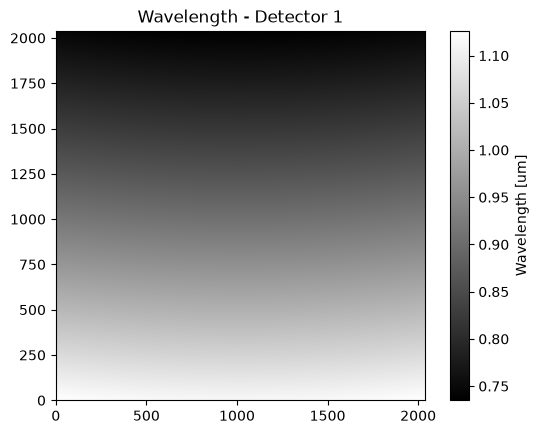

HIERARCH L2 N_NONLINEAR = 0 / number of pixels flagged nonlinear                HIERARCH L2 N_PERSIST = 23502 / number of pixels flagged persist                HIERARCH L2 N_HOT =                    1 / number of pixels flagged hot         HIERARCH L2 N_COLD = 1307 / number of pixels flagged cold                       HIERARCH L2 N_TRAN_NB = 23511 / number of not bad transient pixels              HIERARCH L2 N_PERS_NB = 23498 / number of persistence and not bad pixels        HIERARCH L2 N_SOURCE = 4135535 / number of source flagged pixels                HIERARCH L2 N_XTALK = 53262 / number of crosstalk flagged pixels                HIERARCH L2 N_GHOST = 0 / number of ghost flagged pixels                        HIERARCH L2 N_GHOST_FPA = 0 / number of ghost_fpa flagged pixels                HIERARCH L2 N_GHOST_EXT = 0 / number of ghost_ext flagged pixels                HIERARCH L2 N_BLOOM_NS = 0 / number of BLOOM flagged pixels not flagged SOURCE  HIERARCH L2 N_SNOW_NS = 0 / number of SN

In [2]:
import http.client
import time
import urllib.error

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from astropy import units as u
from astropy.coordinates import SkyCoord

from astroquery.ipac.irsa import Irsa

from firefly_client import FireflyClient

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
from astropy.utils.data import conf
conf.remote_timeout = 120

# example
ra_deg = 304.693508808
dec_deg = 42.4436872991

coord = SkyCoord(ra_deg, dec_deg, unit='deg')
search_radius = 1 * u.arcsec

results = Irsa.query_sia(pos=(coord, search_radius), collection=['spherex_dr1', 'spherex_qr3'])

print(len(results))

print(results.colnames)

spectral_image_url = results['access_url'][0]
print(spectral_image_url)

# Max number of times to retry HTTP errors.
max_retries = 3
for attempt in range(max_retries):
    try:
        # Load the data, reading every extension into memory so that
        # hdulist stays usable after the file is closed.
        with fits.open(spectral_image_url, memmap=False) as hdulist:
            for hdu in hdulist:
                hdu.data
        break
    except (TimeoutError, urllib.error.HTTPError, http.client.IncompleteRead):
        if attempt == max_retries - 1:
            raise
        time.sleep(10 * (attempt + 1))

hdulist.info()

fc = FireflyClient.make_client(url="https://irsa.ipac.caltech.edu/irsaviewer")

fc.reinit_viewer()

fc.show_fits_image(file_input=spectral_image_url,
             plot_id="spectral_image",
             Title="Spectral Image"
             )

spectral_image_header = hdulist[1].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT', 'DETECTOR', 'OBSID', 'DATE', 'PSF_FWHM']

for keyword in keywords_to_print:
    value = spectral_image_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

spectral_image_header['WCSNAME*']

wcs = WCS(spectral_image_header)

print(wcs)

ra, dec = wcs.wcs.crval
x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
print(ra, dec, x, y)

# Load the Spectral WCS from the header.
# Note that we need to provide a reference to HDU List, which contains a lookup table.
spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")

# SIP distortions must be turned off for the spectral WCS.
spectral_wcs.sip = None

# The standard Astropy methods for converting pixel coordinates to world coordinates can also be used to obtain spectral coordinates.
# Take the pixel coordinates that we determined for the image center and resolve them to the wavelength and bandwidth for that pixel
wl, bw = spectral_wcs.pixel_to_world(x, y)
print(wl, bw)

# Read in the spectral image data.
spectral_image = hdulist["IMAGE"]
spectral_image_data = spectral_image.data

# Get arrays of pixel coordinates for the image.
(y, x) = np.indices(spectral_image.shape)

# Use the spectral WCS to convert these pixel coordinates to spectral coordinates.
spectral_coords = spectral_wcs.pixel_to_world(x, y)

# Break out the two spectral coordinates (wavelength and bandwidth) from the spectral coordinates, and print the results.
wavelength, bandwidth = spectral_coords
print("Wavelength: \n", wavelength)
print("Bandwidth: \n", bandwidth)

# Plot the wavelength as a greyscale color map across the image pixels.
plt.imshow(wavelength.value, origin='lower', cmap='gray')
plt.colorbar(label=f"Wavelength [{wavelength.unit}]")

detector = hdulist["IMAGE"].header["DETECTOR"]
plt.title(f"Wavelength - Detector {detector}")
plt.show()

print(spectral_image_header['L2 N_*'])

flags_header = hdulist[2].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT']

for keyword in keywords_to_print:
    value = flags_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

for key in flags_header['MSKN*']:
    bit = key[4:]
    print(f"{int(bit):2d}  {flags_header[key]:<13} {flags_header['MSKD' + bit]}")

variance_header = hdulist[3].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT']

for keyword in keywords_to_print:
    value = variance_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

zodi_header = hdulist[4].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT']

for keyword in keywords_to_print:
    value = zodi_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

psf_header = hdulist["EPSF"].header

keywords_to_print = ['EXTNAME', 'NAXIS2', 'DETECTOR', 'OVSMPX', 'OVSMPY']

for keyword in keywords_to_print:
    value = psf_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

wcs_wave_header = hdulist[6].header
print(wcs_wave_header)

wcs_wave_table = Table(hdulist[6].data)

print("Number of rows:", len(wcs_wave_table))
print("Column names:", wcs_wave_table.colnames)

x_array      = wcs_wave_table["X"][0]
y_array      = wcs_wave_table["Y"][0]
wavelengths  = wcs_wave_table["VALUES"][0]

print("X:",  x_array)
print("Y:",y_array)
print("Dimensions of VALUES array:",  wavelengths.shape)